Q1
Clean: football is my favorite sport because it brings people together i love watching the passionate fans fill the stadium on match day players train hard every day to improve their skills and fitness a single goal in the last minute can change the whole game playing football with friends on weekends is relaxing and fun the beautiful game teaches teamwork discipline and patience
Sentences: ['Football is my favorite sport because it brings people together.', 'I love watching the passionate fans fill the stadium on match day.', 'Players train hard every day to improve their skills and fitness.', 'A single goal in the last minute can change the whole game!', 'Playing football with friends on weekends is relaxing and fun.', 'The beautiful game teaches teamwork, discipline and patience.']
Words: ['football', 'is', 'my', 'favorite', 'sport', 'because', 'it', 'brings', 'people', 'together', 'i', 'love', 'watching', 'the', 'passionate', 'fans', 'fill', 'the', 'stadium', 'on', 'match', 'day

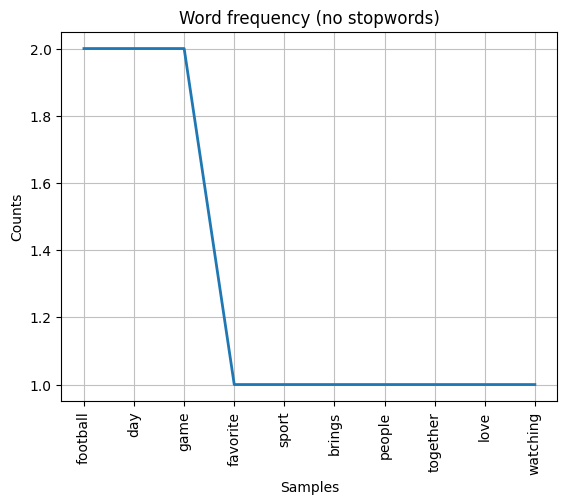

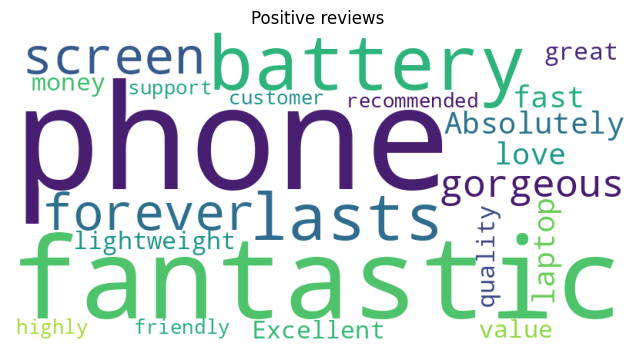


Q6
machine learning is changing the world around us us
deep learning uses neural networks with many layers to
models help help doctors detect disease early early accuracy


In [1]:
!pip install nltk scikit-learn textblob vaderSentiment wordcloud tensorflow matplotlib
import re, nltk, numpy as np
for r in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4']:
    nltk.download(r, quiet=True)
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import FreqDist

stop = set(stopwords.words('english'))
para = ("Football is my favorite sport because it brings people together. "
        "I love watching the passionate fans fill the stadium on match day. "
        "Players train hard every day to improve their skills and fitness. "
        "A single goal in the last minute can change the whole game! "
        "Playing football with friends on weekends is relaxing and fun. "
        "The beautiful game teaches teamwork, discipline and patience.")

# ---------- Q1 ----------
print("Q1")
clean = re.sub(r'[^\w\s]', '', para.lower())
print("Clean:", clean)
print("Sentences:", sent_tokenize(para))
print("Words:", word_tokenize(clean))
print("split():", para.split()[:12])
print("word_tokenize():", word_tokenize(para)[:12])
print("Difference: split() keeps punctuation glued to words ('together.'), "
      "word_tokenize() separates punctuation into its own tokens.")
nostop = [w for w in word_tokenize(clean) if w not in stop]
print("No stopwords:", nostop)
fd = FreqDist(nostop)
print(fd.most_common(10))
fd.plot(10, title="Word frequency (no stopwords)")

# ---------- Q2 ----------
print("\nQ2")
words = re.findall(r'[A-Za-z]+', para.lower())
words = [w for w in words if w not in stop]
stems = [PorterStemmer().stem(w) for w in words]
lem = WordNetLemmatizer()
lems = [lem.lemmatize(w) for w in words]
print("Words     :", words)
print("Stemmed   :", stems)
print("Lemmatized:", lems)
for w, s, l in zip(words, stems, lems):
    if s != l: print(f"{w}: stem={s}, lemma={l}")
print("Stemming is fast and crude (may give non-words like 'passion'->'passion', 'beauti'); "
      "good for search/IR. Lemmatization gives valid dictionary words; prefer it when meaning matters (chatbots, sentiment).")

# ---------- Q3 ----------
print("\nQ3")
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
texts = ["Stock markets rally as tech companies report record profits",
         "The new smartphone has a stunning camera and amazing battery life",
         "Heavy rain and floods disrupt train services across the city"]
cv = CountVectorizer()
bow = cv.fit_transform(texts)
print("BoW vocabulary:", cv.get_feature_names_out())
print(bow.toarray())
tv = TfidfVectorizer()
tf = tv.fit_transform(texts)
names = tv.get_feature_names_out()
print(np.round(tf.toarray(), 2))
for i, row in enumerate(tf.toarray()):
    top = row.argsort()[::-1][:3]
    print(f"Text {i+1} top 3:", [(names[j], round(row[j], 3)) for j in top])
print("Interpretation: words unique to a text (high TF-IDF) like 'smartphone', 'rain', 'stock' "
      "characterise its topic; words shared across texts get lower weight.")

# ---------- Q4 ----------
print("\nQ4")
from sklearn.metrics.pairwise import cosine_similarity
t1 = ("Artificial intelligence enables machines to learn from data. Neural networks recognize patterns "
      "in images and text. AI systems make predictions and automate decisions. Data and computing power drive progress.")
t2 = ("Blockchain is a distributed ledger that records transactions securely. Each block is linked using "
      "cryptographic hashes. Data on the chain is immutable and transparent. Decentralized networks remove the need for trust.")
def prep(t): return [w for w in word_tokenize(re.sub(r'[^\w\s]', '', t.lower())) if w not in stop]
a, b = set(prep(t1)), set(prep(t2))
print("Jaccard:", round(len(a & b) / len(a | b), 3), "common:", a & b)
cs = cosine_similarity(TfidfVectorizer(stop_words='english').fit_transform([t1, t2]))[0, 1]
print("Cosine:", round(cs, 3))
print("Analysis: Jaccard only counts shared unique words (ignores frequency/importance); cosine on TF-IDF "
      "weighs terms by importance, so it gives finer insight. Both are low here since the topics differ.")

# ---------- Q5 ----------
print("\nQ5")
from textblob import TextBlob
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
import matplotlib.pyplot as plt
from wordcloud import WordCloud
reviews = ["This phone is fantastic, the battery lasts forever and the screen is gorgeous!",
           "Terrible service, the delivery was late and the staff were rude.",
           "The product arrived on Tuesday in a brown box.",
           "Absolutely love this laptop, fast, lightweight and great value for money.",
           "Worst purchase ever, it broke after two days and support ignored me.",
           "Excellent quality and friendly customer support, highly recommended!"]
vs = SentimentIntensityAnalyzer()
pos = []
for r in reviews:
    tb = TextBlob(r)
    c = vs.polarity_scores(r)['compound']
    label = 'Positive' if c >= 0.05 else 'Negative' if c <= -0.05 else 'Neutral'
    if label == 'Positive': pos.append(r)
    print(f"{label:8} polarity={tb.sentiment.polarity:.2f} subjectivity={tb.sentiment.subjectivity:.2f} vader={c:.2f} | {r}")
wc = WordCloud(width=800, height=400, background_color='white').generate(' '.join(pos))
plt.figure(figsize=(8, 4)); plt.imshow(wc); plt.axis('off'); plt.title("Positive reviews"); plt.show()

# ---------- Q6 ----------
print("\nQ6")
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from tensorflow.keras.utils import to_categorical
corpus = ("Machine learning is changing the world around us. Computers learn patterns from data and make smart decisions. "
          "Deep learning uses neural networks with many layers to understand images and language. "
          "Researchers train models on large datasets to improve accuracy. These models help doctors detect disease early. "
          "They also power voice assistants and recommendation systems. Learning from data makes machines more useful every day.")
tok = Tokenizer()
tok.fit_on_texts([corpus])
V = len(tok.word_index) + 1
seqs = []
for line in corpus.split('.'):
    ids = tok.texts_to_sequences([line])[0]
    for i in range(2, len(ids) + 1): seqs.append(ids[:i])
L = max(map(len, seqs))
seqs = pad_sequences(seqs, maxlen=L, padding='pre')
X, y = seqs[:, :-1], to_categorical(seqs[:, -1], num_classes=V)
model = Sequential([Embedding(V, 32), LSTM(64), Dense(V, activation='softmax')])
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.fit(X, y, epochs=300, verbose=0)
inv = {i: w for w, i in tok.word_index.items()}
def gen(seed, n=8):
    text = seed
    for _ in range(n):
        s = pad_sequences([tok.texts_to_sequences([text])[0]], maxlen=L - 1, padding='pre')
        text += ' ' + inv.get(int(np.argmax(model.predict(s, verbose=0))), '')
    return text
for seed in ["machine", "deep", "models"]:
    print(gen(seed))